# Predicting EGFR inhibition from chemical structure

**A walkthrough of the whole project, from the cleaned data to the final
predictions.**

EGFR is a protein on the surface of cells that tells them to grow and divide.
When it is stuck in the "on" position, as it is in many non-small-cell lung
cancers, cells keep dividing when they should not. Several approved cancer
drugs work by plugging the protein's active site and switching it off.

This notebook asks a simple question: **given only a drawing of a molecule, can
we predict whether it blocks EGFR?** It then does something less common, which
is the real point of the project: it checks how much of the apparent accuracy is
real, and how much is the model recognising molecules it has effectively already
seen.

### How to read this notebook

Every section has a short plain-language explanation before the code. You do not
need any chemistry to follow it. The three things worth knowing:

| Term | What it means here |
|---|---|
| **IC50** | How much of a compound you need to shut the protein half-way down. **Lower means more potent.** |
| **Active / inactive** | We call a molecule *active* if its IC50 is below 1 µM (1,000 nM), the conventional cutoff. |
| **Fingerprint** | A molecule rewritten as a list of 2,048 yes/no answers, so a computer can compare structures. Explained in section 3. |

### How to run it

```bash
uv sync
uv run jupyter lab notebooks/egfr_analysis.ipynb
```

It runs top to bottom in about three minutes, with no internet connection
needed. It reads the files in `data/` and **does not overwrite anything**: the
model is trained in memory, so running this notebook cannot disturb the
committed results.

Functions are imported from the scripts in `scripts/` wherever possible, rather
than copied, so this notebook and the command-line pipeline cannot drift apart.
See the [README](../README.md) for the written-up version of these results.

## 0. Setup

Loading the project's own scripts as importable modules. Each of the steps
below reuses their functions.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import numpy as np
import pandas as pd
from rdkit.Chem import Draw

# The project's own scripts, imported rather than copied.
import make_fingerprints as fingerprint_script
import train_model as train_script
import evaluate_model as evaluate_script
import experiment_scaffold_split as scaffold_script
import predict_drugs as predict_script

# evaluate_model switches matplotlib to a file-only backend when imported,
# because it is normally run from a terminal. Switch back to inline figures.
%matplotlib inline
import matplotlib.pyplot as plt

DATA = ROOT / "data"

# One hue per job. Blue and vermillion are from the Okabe-Ito palette, which is
# designed to stay distinguishable for the common forms of colour blindness.
ACTIVE_COLOUR, INACTIVE_COLOUR = "#0072B2", "#D55E00"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

print(f"Project root: {ROOT.name}/")
print(f"Fingerprints: radius {fingerprint_script.RADIUS}, "
      f"{fingerprint_script.N_BITS} bits")
print(f"Model:        {train_script.N_TREES} trees, seed {train_script.SEED}, "
      f"{train_script.TEST_FRACTION:.0%} held out for testing")

Project root: egfr-activity-model/
Fingerprints: radius 2, 2048 bits
Model:        500 trees, seed 42, 20% held out for testing


## 1. The data

The measurements come from [ChEMBL](https://www.ebi.ac.uk/chembl/), a public
database of compounds that have been tested against biological targets. We
asked it for every IC50 ever recorded against human EGFR: 25,244 measurements.

`scripts/download_egfr_ic50.py` fetched them and `scripts/clean_and_label.py`
cleaned them. The cleaning mattered more than expected, and is worth reading in
the README, but in short:

- **Not every number is a real number.** ChEMBL records whether a value is exact
  (`=`) or just a limit (`>` or `<`). A result of "greater than 10,000 nM" tells
  you the compound is inactive; "less than 50 nM" cannot be placed either side
  of our cutoff, so it is discarded.
- **Some values are physically impossible.** 155 records were above 1 mM, a few
  as high as 0.8 M, which is more compound than would dissolve. These are
  mostly unit errors: the same compound appears at both 5,220 nM and
  5,220,000 nM. Left in, they flipped labels on genuinely potent compounds.
- **The same compound is measured many times**, in different laboratories, with
  different results. Replicates are merged by taking the **median**, which
  ignores a wild outlier in a way the average would not.

What comes out is one row per unique compound.

In [2]:
labelled = pd.read_csv(DATA / "egfr_labelled.csv")

print(f"{len(labelled):,} unique compounds, each with a structure and a potency\n")
labelled.head()

12,455 unique compounds, each with a structure and a potency



,molecule_chembl_id,smiles,ic50_nM,n_measurements,value_type,label
0,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,53000.0,2,exact,inactive
1,CHEMBL100714,COc1ccc(Nc2ncnc3cc(OC)c(OC)cc23)cc1OC,2800.0,1,exact,inactive
2,CHEMBL1009,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,451440.0,2,exact,inactive
3,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,457.7,1,exact,active
4,CHEMBL101581,COc1cc2nccc(Oc3cccc(Br)c3)c2cc1OC,2500.0,1,exact,inactive


Each row is one compound:

- `smiles` is its structure written as text, which is how chemists type a
  molecule into a computer
- `ic50_nM` is its potency in nanomolar, after merging replicates
- `n_measurements` is how many separate measurements went into that number
- `value_type` is `exact` for a real measurement or `lower_limit` for a
  "greater than" result
- `label` is what the model has to predict

### How many of each class?

This matters for every number later in the notebook. If a dataset is 90% one
class, a model that always guesses that class scores 90%, which looks
impressive and means nothing. So the honest comparison for any accuracy figure
is always *"better than just guessing the commonest answer?"*

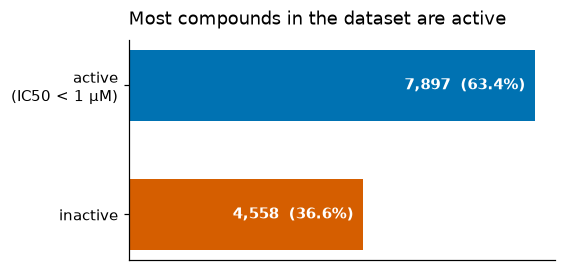

Always guessing 'active' would score 63.4%. That is the number to beat.


In [3]:
counts = labelled["label"].value_counts()
share = counts / counts.sum()

fig, ax = plt.subplots(figsize=(5, 2.6))
bars = ax.barh(
    ["active\n(IC50 < 1 µM)", "inactive"],
    [counts["active"], counts["inactive"]],
    color=[ACTIVE_COLOUR, INACTIVE_COLOUR], height=0.55,
)
for bar, n, pct in zip(bars, counts[["active", "inactive"]], share[["active", "inactive"]]):
    ax.text(bar.get_width() - 180, bar.get_y() + bar.get_height() / 2,
            f"{n:,}  ({pct:.1%})", va="center", ha="right",
            color="white", fontweight="bold")
ax.set_xlabel("compounds")
ax.set_title("Most compounds in the dataset are active", loc="left", pad=10)
ax.invert_yaxis()
ax.get_xaxis().set_visible(False)
plt.show()

print(f"Always guessing 'active' would score {share['active']:.1%}. "
      "That is the number to beat.")

# TODO (interpretation): why is a public bioactivity dataset 63% active, when
# most molecules you could draw would do nothing at all? Write a sentence on
# what that says about which experiments get published, and on which class you
# would therefore expect the model to be weaker at.

## 2. What these molecules actually look like

Before any modelling, it is worth seeing the raw material. Below are three
compounds drawn by RDKit, the chemistry toolkit this project uses, picked by
`pick_examples()` in `scripts/make_fingerprints.py`:

- **the most potent compound in the dataset** that has been measured more than
  once
- **a clearly inactive one**, as a contrast
- **erlotinib**, an approved EGFR drug used in lung cancer, which is in the
  dataset

Note that the potent compound and erlotinib share an obvious family
resemblance: the same flat double-ring core with pieces hung off it. That
resemblance is the entire basis of what follows, and also the trap we spend the
second half of the notebook escaping.

All SMILES were read successfully.

Examples:
  Very active: CHEMBL35820  IC50 = 0.006 nM (active, n=4)
  Inactive: CHEMBL535  IC50 = 18000 nM (inactive, n=13)
  Erlotinib: CHEMBL553  IC50 = 30 nM (active, n=196)


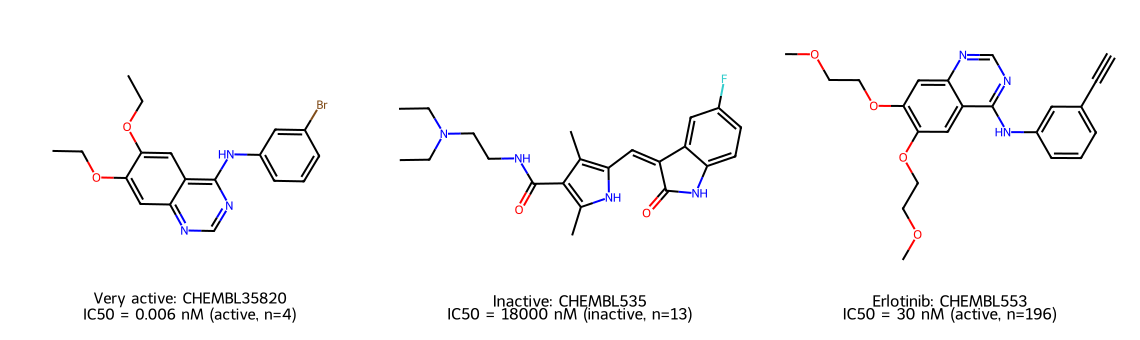

In [4]:
# parse_molecules turns the SMILES text into RDKit molecule objects and reports
# any it cannot read.
molecules = fingerprint_script.parse_molecules(labelled)

print("\nExamples:")
examples = fingerprint_script.pick_examples(molecules)
mols, legends = zip(*examples)
Draw.MolsToGridImage(list(mols), molsPerRow=3, subImgSize=(380, 340),
                     legends=list(legends))

In these drawings each line is a chemical bond and each corner is a carbon atom;
letters mark the atoms that are something other than carbon. The exact chemistry
does not matter here. What matters is that the first and third molecules are
built around the same core, and the middle one is not.

Note the potency range on display: the active example is roughly **a million
times** more potent than the inactive one. That is why potencies are discussed
on a log scale, and why a single 1 µM cutoff is a blunt instrument.

## 3. Turning a molecule into numbers

A random forest cannot read a molecular structure, so each molecule has to
become a row of numbers. The standard trick is a **Morgan fingerprint**.

Walk up to every atom in the molecule and look at its immediate neighbourhood:
the atom itself, then everything within one bond, then everything within two
bonds. Each distinct neighbourhood you find ("an oxygen attached to two
carbons, one of which is in a ring...") gets hashed to a slot in a list of
2,048 slots, and that slot is set to 1.

The result is 2,048 yes/no answers to the question *"does this molecule contain
this particular local arrangement of atoms?"*

Two things follow, and both matter later:

- **Two molecules with similar fingerprints are structurally similar.** This is
  what makes prediction possible at all: the model learns which substructures
  tend to show up in compounds that block EGFR.
- **The fingerprint throws information away.** It records which pieces are
  present, not how they are arranged in 3D, and in particular it **ignores
  stereochemistry** - the handedness of a molecule. Two mirror-image molecules,
  which can differ enormously in a real body, get *identical* fingerprints.
  Hold on to that; it causes a real problem in section 7.

The code below rebuilds the fingerprints from scratch and checks they match the
committed `data/egfr_fingerprints.npz`, so you can see the pipeline reproduce
itself.

In [5]:
X = fingerprint_script.make_fingerprints(molecules["mol"])
y = (molecules["label"] == "active").astype(np.uint8).to_numpy()
ids = molecules["molecule_chembl_id"].to_numpy()
smiles = molecules["smiles"].to_numpy()

print(f"X is a table of {X.shape[0]:,} molecules x {X.shape[1]:,} bits")
print(f"On average {X.sum(axis=1).mean():.0f} of {X.shape[1]:,} bits are "
      f"switched on, so each fingerprint is mostly zeros.")

# Reproducibility check against the file the script wrote.
stored = np.load(DATA / "egfr_fingerprints.npz", allow_pickle=True)
assert np.array_equal(X, stored["X"]) and np.array_equal(y, stored["y"])
print("\nIdentical to data/egfr_fingerprints.npz, so this notebook reproduces "
      "the pipeline exactly.")

X is a table of 12,455 molecules x 2,048 bits
On average 61 of 2,048 bits are switched on, so each fingerprint is mostly zeros.

Identical to data/egfr_fingerprints.npz, so this notebook reproduces the pipeline exactly.


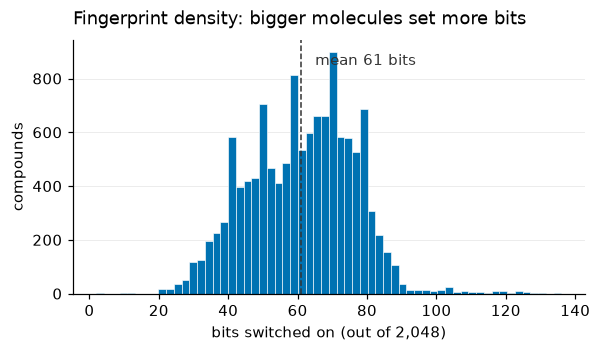

In [6]:
bits_set = X.sum(axis=1)

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(bits_set, bins=60, color=ACTIVE_COLOUR, edgecolor="white", linewidth=0.4)
ax.axvline(bits_set.mean(), color="#333333", linestyle="--", linewidth=1)
ax.text(bits_set.mean() + 4, ax.get_ylim()[1] * 0.9,
        f"mean {bits_set.mean():.0f} bits", color="#333333")
ax.set_xlabel("bits switched on (out of 2,048)")
ax.set_ylabel("compounds")
ax.set_title("Fingerprint density: bigger molecules set more bits",
             loc="left", pad=10)
ax.grid(axis="y", alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)
plt.show()

# TODO (interpretation): roughly 97% of every fingerprint is zeros. Note what
# you think that sparsity means for a model that has to find patterns in it,
# and whether the long right-hand tail (very large molecules) worries you.

## 4. Training the model

### What a random forest is

A **decision tree** is a game of twenty questions: *does the molecule have
substructure #412? If yes, does it have #1879?* ... until it commits to an
answer. One tree is easy to understand and unreliable, because it latches onto
quirks of the particular compounds it was shown.

A **random forest** builds 500 such trees, each on a random subsample of the
data and allowed to consider only a random subset of the fingerprint bits at
each question. No two trees are the same. To predict, all 500 vote, and the
share of votes for "active" becomes the model's probability.

Averaging many deliberately different trees cancels out their individual
quirks. Random forests also cope well with exactly our shape of problem: a
great many binary features, most of them irrelevant.

### What a stratified split is

The model is trained on 80% of the compounds and tested on the other 20%, which
it never sees during training. **Stratified** means the split keeps both halves
at the same 63% active mix as the full dataset, instead of letting the random
draw hand us a test set that happens to be 75% active and therefore flatters the
model. The random seed is fixed, so the split is identical every time anyone
runs this.

### One setting worth flagging

`class_weight="balanced"` tells the forest to treat each inactive compound as
more important during training, to compensate for actives outnumbering them.
Section 6 shows what this buys and what it costs.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, ids,
    test_size=train_script.TEST_FRACTION,
    stratify=y,                      # keep the active/inactive mix in both halves
    random_state=train_script.SEED,  # same split every run
)
print(f"Train: {len(y_train):,} compounds ({y_train.mean():.1%} active)")
print(f"Test:  {len(y_test):,} compounds ({y_test.mean():.1%} active)")

# Same split as the committed one, so the notebook and the scripts agree.
committed = pd.read_csv(DATA / "egfr_split.csv").set_index("molecule_chembl_id")["set"]
assert set(ids_test) == set(committed[committed == "test"].index)
print("\nThis is the same test set as data/egfr_split.csv.")

Train: 9,964 compounds (63.4% active)
Test:  2,491 compounds (63.4% active)

This is the same test set as data/egfr_split.csv.


In [8]:
# Identical settings to scripts/train_model.py, trained here in memory so the
# notebook does not overwrite models/egfr_random_forest.joblib.
model = RandomForestClassifier(
    n_estimators=train_script.N_TREES,
    n_jobs=-1,
    random_state=train_script.SEED,
    class_weight="balanced",
)
model.fit(X_train, y_train)
print(f"Trained {train_script.N_TREES} trees on {len(y_train):,} compounds.")

Trained 500 trees on 9,964 compounds.


## 5. How good is it?

Four ways of asking, because accuracy alone hides the interesting part.

- **Accuracy** - what fraction of the test compounds it got right. Always
  compare it to the 63% you would get by calling everything active.
- **Recall, per class** - of the compounds that really are active, how many did
  it find? And separately, of the ones that really are inactive, how many did it
  correctly reject? A model can have good accuracy while being nearly useless at
  one of the two.
- **Precision, per class** - when it says "active", how often is that right?
- **ROC-AUC** - the model does not just say active or inactive, it gives a
  probability. ROC-AUC asks: pick one real active and one real inactive at
  random; how often does the model score the active one higher? 0.5 is coin
  flipping, 1.0 is perfect. It is useful because it judges the *ranking* of
  compounds, independently of where you draw the 0.5 cutoff - which is what you
  care about if you are using the model to decide which 100 compounds to test
  first.

In [9]:
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score)

predicted = model.predict(X_test)
p_active = model.predict_proba(X_test)[:, 1]   # probability of "active"

accuracy = accuracy_score(y_test, predicted)
baseline = y_test.mean()

print(f"Accuracy:                 {accuracy:.1%}")
print(f"Always guessing 'active': {baseline:.1%}")
print(f"Improvement:              {(accuracy - baseline) * 100:+.1f} points")
print(f"ROC-AUC:                  {roc_auc_score(y_test, p_active):.3f}\n")

# evaluate_script.NAMES is ["inactive", "active"], matching labels 0 and 1.
print(classification_report(y_test, predicted,
                            target_names=evaluate_script.NAMES, digits=3))

Accuracy:                 88.0%
Always guessing 'active': 63.4%
Improvement:              +24.6 points
ROC-AUC:                  0.941

              precision    recall  f1-score   support

    inactive      0.829     0.846     0.838       912
      active      0.910     0.899     0.905      1579

    accuracy                          0.880      2491
   macro avg      0.870     0.873     0.871      2491
weighted avg      0.881     0.880     0.880      2491



### The confusion matrix

A 2x2 table of truth against prediction. The diagonal is what the model got
right; the off-diagonal is the two different ways of being wrong, which have
very different costs. A **false positive** (an inactive compound called active)
wastes a few weeks of laboratory time. A **false negative** (a real inhibitor
thrown away) is a drug you never find.

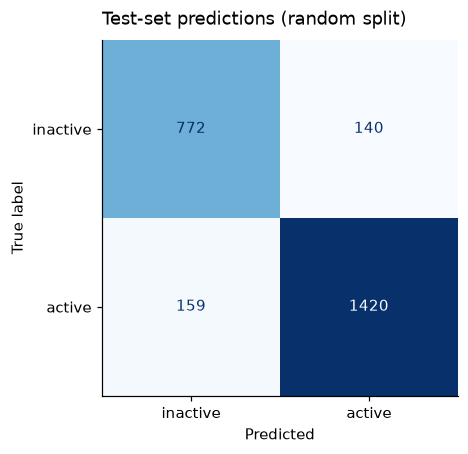

                called inactive  called active
truly inactive              772            140
truly active                159           1420


In [10]:
matrix = confusion_matrix(y_test, predicted)

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ConfusionMatrixDisplay(matrix, display_labels=evaluate_script.NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("Test-set predictions (random split)", loc="left", pad=10)
ax.set_xlabel("Predicted")
ax.set_ylabel("True label")
ax.grid(False)
plt.show()

print(pd.DataFrame(matrix, index=[f"truly {n}" for n in evaluate_script.NAMES],
                   columns=[f"called {n}" for n in evaluate_script.NAMES]).to_string())

# TODO (interpretation): compare the two off-diagonal cells. Which mistake does
# this model make more often, and is that the mistake you would rather it made
# if you were using it to choose compounds to buy and test? Say so explicitly.

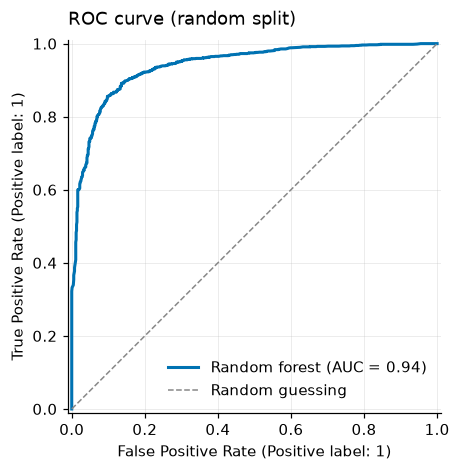

In [11]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
RocCurveDisplay.from_predictions(
    y_test, p_active, ax=ax, name="Random forest",
    curve_kwargs={"color": ACTIVE_COLOUR, "linewidth": 2},
    plot_chance_level=True,
    chance_level_kw={"color": "#888888", "linestyle": "--", "linewidth": 1,
                     "label": "Random guessing"},
)
ax.set_title("ROC curve (random split)", loc="left", pad=10)
ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)
plt.show()

The curve shows the trade-off available to you as you move the cutoff. Sliding
it towards "call almost everything active" catches nearly every real inhibitor
(top right) but drags in a pile of duds. Sliding it the other way makes the
model's "active" calls very trustworthy but misses most real hits. The further
the curve bulges towards the top-left corner, the better the model is at every
cutoff at once, and the area under it is the ROC-AUC quoted above.

**At this point the project looks finished, with a good-looking result.** The
rest of the notebook is about why that result is too good.

## 6. The honest test: splitting by scaffold

### What a scaffold is

Take a molecule and strip off everything hanging around the outside, keeping
only the rings and the bits of chain that connect them. What is left is the
**Bemis-Murcko scaffold** - the molecule's skeleton.

Scaffolds matter because of how medicinal chemistry is done. A team finds one
promising molecule and then makes two hundred variations on it, swapping a
group here and a chain there, publishing the whole series. All two hundred share
one scaffold. They are, for our purposes, nearly the same molecule.

### Why that breaks the result above

The random split in section 4 scattered those two hundred siblings at random: a
compound in the test set almost always has close relatives sitting in the
training set. So when the model "predicts" it, the honest description is closer
to *looking up the answer for its near-twin*. That is **data leakage**, and it is
why the 88% above is not a real estimate of performance on new chemistry.

The fix is a **scaffold split**: group compounds by skeleton, then assign whole
groups to training or test. Now every test compound belongs to a chemical series
the model has never seen in any form. The split is still 80/20 and still
deterministic, with the largest series going to training.

This is a harder test, and that is the point. It answers the question you
actually have, which is not "can it recognise relatives of things it has seen?"
but **"would it have found something new?"**

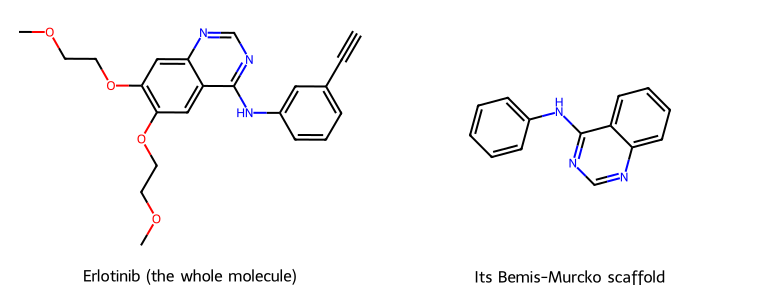

In [12]:
# What a scaffold looks like: erlotinib, stripped to its skeleton.
erlotinib = labelled.loc[labelled["molecule_chembl_id"] == "CHEMBL553"].iloc[0]
scaffold = scaffold_script.scaffold_of(erlotinib["smiles"])

from rdkit import Chem
Draw.MolsToGridImage(
    [Chem.MolFromSmiles(erlotinib["smiles"]), Chem.MolFromSmiles(scaffold)],
    molsPerRow=2, subImgSize=(380, 300),
    legends=["Erlotinib (the whole molecule)", "Its Bemis-Murcko scaffold"],
)

Everything decorative is gone and the bare two-ring core remains. Every compound
in the dataset built on that core, however differently decorated, now counts as
the same series.

In [13]:
# scaffold_split groups by skeleton and assigns whole groups, largest first.
assignment = scaffold_script.scaffold_split(smiles)
scaffold_train = assignment == "train"
scaffold_test = assignment == "test"

print(f"\nTrain: {scaffold_train.sum():,} compounds "
      f"({y[scaffold_train].mean():.1%} active)")
print(f"Test:  {scaffold_test.sum():,} compounds "
      f"({y[scaffold_test].mean():.1%} active)")

scaffold_model = RandomForestClassifier(
    n_estimators=train_script.N_TREES, n_jobs=-1,
    random_state=train_script.SEED, class_weight="balanced",
)
scaffold_model.fit(X[scaffold_train], y[scaffold_train])
print(f"\nTrained an identical forest on the scaffold-split training set.")

4500 distinct scaffolds across 12455 molecules; largest group has 673 molecules

Train: 9,964 compounds (65.7% active)
Test:  2,491 compounds (54.4% active)



Trained an identical forest on the scaffold-split training set.


In [14]:
# scaffold_script.score returns accuracy, ROC-AUC and per-class recall.
comparison = pd.DataFrame({
    "random split": scaffold_script.score(model, X_test, y_test),
    "scaffold split": scaffold_script.score(
        scaffold_model, X[scaffold_test], y[scaffold_test]),
}).T
comparison["always_guess_active"] = comparison["percent_active"]

shown = comparison.drop(columns=["percent_active"]).copy()
shown["molecules"] = shown["molecules"].astype(int)
for column in ["accuracy", "recall_active", "recall_inactive", "always_guess_active"]:
    shown[column] = (shown[column] * 100).round(1).astype(str) + "%"
shown["roc_auc"] = comparison["roc_auc"].round(3)
shown

,molecules,accuracy,roc_auc,recall_active,recall_inactive,always_guess_active
random split,2491,88.0%,0.941,89.9%,84.6%,63.4%
scaffold split,2491,79.6%,0.866,85.4%,72.6%,54.4%


In [15]:
drop_accuracy = (comparison.loc["random split", "accuracy"]
                 - comparison.loc["scaffold split", "accuracy"]) * 100
drop_auc = (comparison.loc["random split", "roc_auc"]
            - comparison.loc["scaffold split", "roc_auc"])

print(f"Moving to new chemistry costs {drop_accuracy:.1f} points of accuracy "
      f"and {drop_auc:.3f} of ROC-AUC.")
print("Both splits still beat their own always-guess-active baseline by "
      "more than 20 points, so the model is learning something real.")

# TODO (interpretation): the gap is the headline finding of this project. In two
# or three sentences, say which of the two numbers you would quote to someone
# deciding whether to use this model, and why. Then look at inactive recall in
# the table above: it falls much further than active recall. Offer an
# explanation (section 1's class imbalance is a hint).

Moving to new chemistry costs 8.4 points of accuracy and 0.075 of ROC-AUC.
Both splits still beat their own always-guess-active baseline by more than 20 points, so the model is learning something real.


### Also worth knowing: class weighting

A third experiment, `scripts/experiment_class_weight.py`, tested
`class_weight="balanced"` on this scaffold split. It raises inactive recall from
62.4% to 72.6%, at a cost of 3.7 points of active recall - a better trade for
screening, where a false positive costs real laboratory time.

The telling detail is that **ROC-AUC barely moved** (0.868 to 0.866). The
setting did not teach the model anything new; it only moved where the decision
cutoff sits. Any further improvement has to come from giving the model
genuinely new information, not from recalibration.

In [16]:
pd.read_csv(DATA / "class_weight_comparison.csv", index_col=0)

,accuracy,roc_auc,recall_active,recall_inactive,balanced_accuracy
unweighted (before),0.768768,0.868400,0.890694,0.623571,0.757133
balanced (after),0.795664,0.865939,0.853767,0.726473,0.790120


## 7. Does it recognise real drugs?

The obvious sanity check: show the model five approved EGFR inhibitors that are
genuinely used in patients, plus four everyday drugs that have nothing to do
with EGFR, and see whether it can tell them apart.

The structures below were looked up in ChEMBL by `scripts/predict_drugs.py`;
they are read from its saved output here so the notebook needs no internet.

Alongside each prediction we report the **Tanimoto similarity to the most
similar compound in the training set** - a 0-to-1 measure of fingerprint
overlap, where above about 0.7 means the same chemical series and 1.0 means an
identical fingerprint. This is the single most important column in the table,
because a confident prediction about a molecule unlike anything the model has
seen is not a prediction, it is a guess. Reporting it is what keeps the model
honest about its own **applicability domain**.

In [17]:
from rdkit import DataStructs

panel = pd.read_csv(DATA / "drug_predictions.csv")[
    ["name", "expected", "smiles", "chembl_id"]
]

# Reuse the script's own fingerprint generator and training-set loader, so the
# similarity here is computed exactly as the command-line tool computes it.
training_fingerprints, training_ids = predict_script.load_training_set()
mols = [Chem.MolFromSmiles(s) for s in panel["smiles"]]
panel_X = np.array([predict_script.GENERATOR.GetFingerprintAsNumPy(m) for m in mols])

rows = []
for (_, drug), mol, probability in zip(
    panel.iterrows(), mols, model.predict_proba(panel_X)[:, 1]
):
    similarities = DataStructs.BulkTanimotoSimilarity(
        predict_script.GENERATOR.GetFingerprint(mol), training_fingerprints
    )
    best = int(np.argmax(similarities))
    rows.append({
        "drug": drug["name"],
        "truth": drug["expected"],
        "p_active": round(float(probability), 3),
        "predicted": "active" if probability >= 0.5 else "inactive",
        "nearest_similarity": round(float(similarities[best]), 2),
        "nearest_compound": training_ids[best],
        # warning_for turns that similarity into a plain-language caveat.
        "reliability": predict_script.warning_for(float(similarities[best])),
    })

pd.DataFrame(rows)

,drug,truth,p_active,predicted,nearest_similarity,nearest_compound,reliability
0,Gefitinib,EGFR inhibitor,0.982,active,1.00,CHEMBL939,IN TRAINING DATA - score reflects memorisation...
1,Erlotinib,EGFR inhibitor,0.994,active,1.00,CHEMBL553,IN TRAINING DATA - score reflects memorisation...
2,Afatinib,EGFR inhibitor,0.996,active,1.00,CHEMBL1173655,IN TRAINING DATA - score reflects memorisation...
3,Osimertinib,EGFR inhibitor,0.992,active,1.00,CHEMBL3353410,IN TRAINING DATA - score reflects memorisation...
4,Lapatinib,EGFR inhibitor,1.000,active,1.00,CHEMBL554,IN TRAINING DATA - score reflects memorisation...
5,Aspirin,control,0.014,inactive,1.00,CHEMBL25,IN TRAINING DATA - score reflects memorisation...
6,Paracetamol,control,0.022,inactive,0.48,CHEMBL57631,related to training data - moderate confidence
7,Caffeine,control,0.185,inactive,0.26,CHEMBL4525168,UNLIKE ANYTHING IN TRAINING DATA - do not trus...
8,Ibuprofen,control,0.024,inactive,1.00,CHEMBL521,IN TRAINING DATA - score reflects memorisation...


### Reading this table carefully

All five EGFR drugs score above 0.97 and all four controls are called inactive.
Taken at face value, that is a perfect result.

Look at the similarity column. Every one of the five drugs has a nearest
training neighbour at or near 1.00, because **all five are in ChEMBL and
therefore in the training data.** The model is not predicting them, it is
remembering them. As a test of the model this proves nothing at all.

`scripts/experiment_holdout_drugs.py` deals with that by removing the five drugs
by ChEMBL ID and retraining. All five are still called active - but measuring
each drug's nearest *remaining* neighbour turned up something better than the
headline:

- **afatinib**: similarity 1.00 to its own mirror image. The opposite
  enantiomer is a separate ChEMBL entry, and because Morgan fingerprints ignore
  handedness (section 3), it is literally the same input to the model.
- **erlotinib**: 0.98 to its own hydrochloride salt, a different ChEMBL entry.
- **osimertinib**: 0.91 to a deuterated version of itself.

So deleting a compound by its database ID does not remove it from the training
set. This is the finding that motivated the scaffold split in section 6, and the
reason the honest number to quote is 79.6% rather than 88.0%.

In [18]:
pd.read_csv(DATA / "holdout_experiment.csv")

# TODO (interpretation): the controls (aspirin, paracetamol, caffeine,
# ibuprofen) have low similarity to anything in training, so by the model's own
# standard its confident "inactive" calls for them are unreliable. Do you
# nonetheless believe them, and why? This is a genuine judgement call about what
# a nearest-neighbour similarity can and cannot tell you.

,drug,chembl_id,p_active_before,p_active_after,closest_in_training,predicted_after,change
0,Gefitinib,CHEMBL939,0.982,0.960,0.92,active,-0.022
1,Erlotinib,CHEMBL553,0.994,0.992,0.98,active,-0.002
2,Afatinib,CHEMBL1173655,0.996,0.984,1.00,active,-0.012
3,Osimertinib,CHEMBL3353410,0.992,0.982,0.91,active,-0.010
4,Lapatinib,CHEMBL554,1.000,1.000,0.87,active,0.000


## 8. Where this leaves us

**The model works, and the honest number is the smaller one.** On genuinely new
chemistry it gets about 80% of compounds right with a ROC-AUC of 0.87, well
clear of the 54% you would get by guessing. It would be useful for ranking a
library of compounds to decide which to test first. It is not a substitute for
testing them.

**The gap between 88% and 80% is the part worth carrying forward.** Most of that
8 points came from near-duplicates straddling the train/test boundary -
enantiomers, salts, isotopic variants, and whole published series of close
analogues. None of that is visible if you only run the standard random split,
which is exactly why the standard random split is reported so often.

### Honest limitations

- **2D structure only.** Fingerprints know which fragments are present, not
  their 3D shape, how the molecule actually sits in the binding site, or whether
  it hits other kinases too.
- **One arbitrary cutoff.** 1 µM is conventional, but a compound at 900 nM and
  one at 1,100 nM are chemically indistinguishable and land in opposite classes.
- **Publication bias.** 63% actives, because papers report series built around
  compounds that worked. True inactives are under-represented and chemically
  scattered, which is why inactive recall is the weakest number in every table
  here.
- **Pooled assays.** IC50 values come from many laboratories and assay formats;
  the median helps but does not fix it.

### What I would do next

- Add physicochemical descriptors (logP, TPSA, molecular weight) alongside the
  fingerprint bits. Since class weighting moved ROC-AUC not at all, further
  gains need new information rather than recalibration.
- Deduplicate by canonical parent structure (InChIKey) to collapse the salt,
  isotope and stereoisomer twins found in section 7.
- Predict pIC50 as a number instead of a binary label, which stops throwing away
  potency information at the cutoff.
- Benchmark against a graph neural network, which sees the molecule as a
  connected structure rather than a bag of fragments.

```
TODO (interpretation): close with your own take. Two questions worth answering:
  1. If a colleague asked you "should I use this to pick compounds?", what would
     you actually say, and what would you warn them about?
  2. Which of the four next steps above would you do first, and why that one?
```